# D. Arus asal–tujuan dan daya tarik kapanewon di DIY

**Pertanyaan:** Dari mana perangkat pengunjung tiap kapanewon berasal, kapanewon mana yang paling banyak didatangi perangkat dari wilayah lain, dan apakah pola jam puncak dari bagian B sejalan dengan daya tarik itu?

**Periode:** Desember 2021–Februari 2022. Data OD Maret–April 2022 ditandai `reduced_quality = True` oleh pembuat dataset, jadi hanya dipakai di uji sensitivitas.

**Masukan:**
- `od_home_visits_kapanewon_monthly.csv` dan `od_origin_homes_monthly.csv` dari [JogjaPulse](https://zenodo.org/records/23157460).
- `data/processed/B_klaster_kapanewon.csv` dari [notebook B](B_klaster_kapanewon.ipynb), yang membutuhkan hasil [notebook A](A_ritme_harian.ipynb).
- `data/external/batas_kapanewon.geojson` dari [Geoportal DIY](https://geoportal.jogjaprov.go.id/server/rest/services/ADMIN_BATASWILAYAH/DIY_34_ADMINISTRASIKEC_AR/FeatureServer/0), digabung lewat kode BPS.

**Cara membaca data OD.** Satu baris adalah jumlah perangkat unik yang rumah bulanannya di kapanewon asal dan teramati minimal sekali di kapanewon tujuan pukul 08.00–17.59 WIB pada bulan yang sama. Angka ini menghitung pengunjung, bukan perjalanan. Rumah bulanan ditentukan dari lokasi malam (22.00–05.59), jadi tidak sama dengan alamat terverifikasi. Baris dengan kurang dari 5 perangkat dihapus.

**Aturan penjumlahan.** Setiap perangkat hanya punya satu rumah per bulan, sehingga `n_maids` boleh dijumlahkan antar kapanewon **asal** untuk satu tujuan. Sebaliknya, satu perangkat bisa mengunjungi banyak tujuan, sehingga `n_maids` **tidak boleh** dijumlahkan antar tujuan. Karena itu matriks di bawah memakai kapanewon tujuan, bukan kabupaten tujuan.

In [1]:
from pathlib import Path
import sys

root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "ritme" / "io.py").is_file()),
    None,
)
if root is None:
    raise RuntimeError("Buka notebook dari folder ritme-jogja atau notebooks/.")
sys.path.insert(0, str(root / "src"))

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
from scipy import stats

from ritme import io, maps, style

style.apply()

BULAN = io.MONTHS_GOOD_QUALITY
BULAN_SEMUA = ["2021-12", "2022-01", "2022-02", "2022-03", "2022-04"]
SEED = 42
N_PERMUTASI = 9999
KLASTER_UTAMA = ["Puncak siang", "Puncak petang"]
WARNA_KLASTER = dict(zip([*KLASTER_UTAMA, "Profil tak lazim"], style.CATEGORICAL[:3]))

od_semua = io.load_od_visits()
rumah_semua = io.load_od_origin_homes()
lookup = io.kapanewon_lookup()

klaster_path = io.PROCESSED_DIR / "B_klaster_kapanewon.csv"
if not klaster_path.is_file():
    raise FileNotFoundError(f"{klaster_path} belum ada. Jalankan notebook A lalu notebook B.")
klaster = pd.read_csv(klaster_path, dtype={"kapanewon_code": "string", "kab_code": "string"})

if len(lookup) != 78 or len(klaster) != 78:
    raise ValueError("Lookup kapanewon dan hasil B harus berisi 78 kapanewon.")
if sorted(od_semua["month"].unique()) != BULAN_SEMUA:
    raise ValueError("Bulan di file OD tidak sesuai dengan dokumentasi dataset.")
if rumah_semua.duplicated(["month", "origin_code"]).any():
    raise ValueError("Penyebut OD harus satu baris per bulan dan kode asal.")
if od_semua.duplicated(["month", "origin_code", "dest_code"]).any():
    raise ValueError("Data OD harus satu baris per bulan, asal, dan tujuan.")

nama = lookup.set_index("kapanewon_code")["kapanewon"].str.title()
kab = lookup.set_index("kapanewon_code")["kab_kota"]
print(f"OD {len(od_semua):,} baris, penyebut {len(rumah_semua)} baris, {len(lookup)} kapanewon.")

OD 9,894 baris, penyebut 390 baris, 78 kapanewon.


## 1. Cakupan data OD

Sebelum menghitung proporsi, kami cek berapa perangkat yang punya rumah bulanan dan berapa yang teramati siang hari. Penyebut semua proporsi adalah `n_homed_maids_daytime`, yaitu perangkat ber-rumah yang juga teramati pukul 08.00–17.59. Penyebut ini juga turun dari bulan ke bulan karena perubahan sampel, jadi perbandingan antar bulan memakai proporsi, bukan jumlah mentah.

In [2]:
cakupan = (
    rumah_semua.groupby("month")
    .agg(
        kapanewon_asal=("origin_code", "nunique"),
        perangkat_berumah=("n_homed_maids", "sum"),
        perangkat_berumah_siang=("n_homed_maids_daytime", "sum"),
        penyebut_kosong=("n_homed_maids_daytime", lambda s: int(s.isna().sum())),
    )
    .join(od_semua.groupby("month").size().rename("baris_od"))
    .join(od_semua.groupby("month")["reduced_quality"].first())
)
display(cakupan)
display(io.load_od_summary())

rumah = rumah_semua[rumah_semua["month"].isin(BULAN)].copy()
od = od_semua[od_semua["month"].isin(BULAN)].copy()
if rumah["n_homed_maids_daytime"].isna().any() or rumah.groupby("month").size().ne(78).any():
    raise ValueError("Periode utama harus punya penyebut siang untuk 78 kapanewon setiap bulan.")

penyebut = rumah.set_index(["month", "origin_code"])["n_homed_maids_daytime"].astype(float)
od["penyebut"] = penyebut.reindex(pd.MultiIndex.from_frame(od[["month", "origin_code"]])).to_numpy()
od["proporsi"] = od["n_maids"] / od["penyebut"]
if od["penyebut"].isna().any() or od["proporsi"].gt(1).any():
    raise ValueError("Setiap baris OD harus punya penyebut, dan proporsi tidak boleh di atas 1.")

lokal = od[od["origin_code"] == od["dest_code"]]
print(
    "Perangkat yang teramati siang di kapanewon rumahnya sendiri: median "
    f"{lokal['proporsi'].median():.1%}, rentang {lokal['proporsi'].min():.1%}–{lokal['proporsi'].max():.1%} "
    f"({len(lokal)} pasangan kapanewon × bulan)."
)

,kapanewon_asal,perangkat_berumah,perangkat_berumah_siang,penyebut_kosong,baris_od,reduced_quality
month,,,,,,
2021-12,78,122182,112475,0,2595,False
2022-01,78,86013,77312,0,2624,False
2022-02,78,77723,64269,0,2653,False
2022-03,78,23185,12305,0,1202,True
2022-04,78,14272,11624,0,820,True


,k,min_nights,od_rows_total,od_rows_published,od_rows_suppressed_pct,inter_zonal_flow_kept_pct,origin_rows_published
0,5,2,19263,9894,48.6,95.3,390


Perangkat yang teramati siang di kapanewon rumahnya sendiri: median 94.1%, rentang 45.5%–100.0% (234 pasangan kapanewon × bulan).


Sekitar 95% arus antar kapanewon tetap terbit setelah supresi (`inter_zonal_flow_kept_pct`). Sisanya hilang di pasangan kecil, sehingga semua angka daya tarik di bawah adalah **batas bawah**. Uji sensitivitas di bagian 5 menghitung batas atasnya.

Hampir semua perangkat teramati siang hari di kapanewon rumahnya sendiri. Proporsi tujuan lain karena itu kecil (umumnya di bawah 20%), dan satu perangkat bisa tercatat di rumah sekaligus di tujuan lain.

## 2. Matriks asal–tujuan: kabupaten asal ke kapanewon tujuan

Untuk kabupaten asal *K* dan kapanewon tujuan *j*, kami menghitung persentase perangkat ber-rumah di *K* yang teramati siang di *j*:

`jumlah n_maids dari semua kapanewon asal i di K (i ≠ j) / jumlah n_homed_maids_daytime kapanewon i yang sama`

Penghuni *j* sendiri dikeluarkan dari pembilang dan penyebut, sehingga angkanya selalu berarti kunjungan dari kapanewon lain. Nilai dihitung per bulan lalu dirata-ratakan untuk Desember–Februari. Tujuan yang ditampilkan adalah tiga tujuan teratas tiap kabupaten asal.

In [3]:
def matriks_kabupaten(od_bulan, rumah_bulan):
    luar = od_bulan[od_bulan["origin_code"] != od_bulan["dest_code"]]
    pembilang = luar.groupby(["month", "origin_kab_kota", "dest_code"])["n_maids"].sum()
    total_kab = rumah_bulan.groupby(["month", "origin_kab_kota"])["n_homed_maids_daytime"].sum()
    hasil = pembilang.reset_index()
    hasil["penyebut"] = total_kab.reindex(
        pd.MultiIndex.from_frame(hasil[["month", "origin_kab_kota"]])
    ).to_numpy()
    # Keluarkan penghuni tujuan dari penyebut bila tujuan ada di kabupaten asal yang sama.
    sendiri = rumah_bulan.set_index(["month", "origin_code"])["n_homed_maids_daytime"]
    satu_kab = hasil["dest_code"].map(kab).eq(hasil["origin_kab_kota"])
    kurangi = sendiri.reindex(pd.MultiIndex.from_frame(hasil[["month", "dest_code"]])).to_numpy()
    hasil["penyebut"] = hasil["penyebut"] - np.where(satu_kab, kurangi, 0)
    hasil["persen"] = hasil["n_maids"] / hasil["penyebut"] * 100
    return hasil


mat_bulanan = matriks_kabupaten(od, rumah)
mat = mat_bulanan.groupby(["origin_kab_kota", "dest_code"])["persen"].mean().unstack("origin_kab_kota")
mat = mat.reindex(columns=style.KAB_ORDER).fillna(0)

tujuan_pilih = sorted({kode for k in style.KAB_ORDER for kode in mat[k].nlargest(3).index})
tujuan_pilih = sorted(tujuan_pilih, key=lambda c: (style.KAB_ORDER.index(kab[c]), -mat.loc[c].max()))
tampil = mat.loc[tujuan_pilih]
tampil.index = [f"{nama[c]} ({style.KAB_LABELS[kab[c]]})" for c in tujuan_pilih]
tampil.columns = [style.KAB_LABELS[k] for k in tampil.columns]
tampil.round(1)

,Kota Yogyakarta,Sleman,Bantul,Kulon Progo,Gunungkidul
Umbulharjo (Kota Yogyakarta),24.8,3.5,8.1,1.6,2.2
Gondokusuman (Kota Yogyakarta),18.7,5.9,4.4,2.5,2.2
Depok (Sleman),15.9,15.4,8.5,6.2,6.9
Ngaglik (Sleman),5.9,11.3,3.0,6.1,3.4
Mlati (Sleman),6.3,9.3,3.0,1.9,1.1
Banguntapan (Bantul),18.1,6.6,6.8,3.4,5.8
Sewon (Bantul),5.8,1.8,8.1,1.5,0.7
Wates (Kulon Progo),2.2,1.4,1.3,15.1,2.0
Pengasih (Kulon Progo),0.8,0.6,0.5,10.7,0.3
Wonosari (Gunungkidul),2.3,1.6,1.5,1.8,19.6


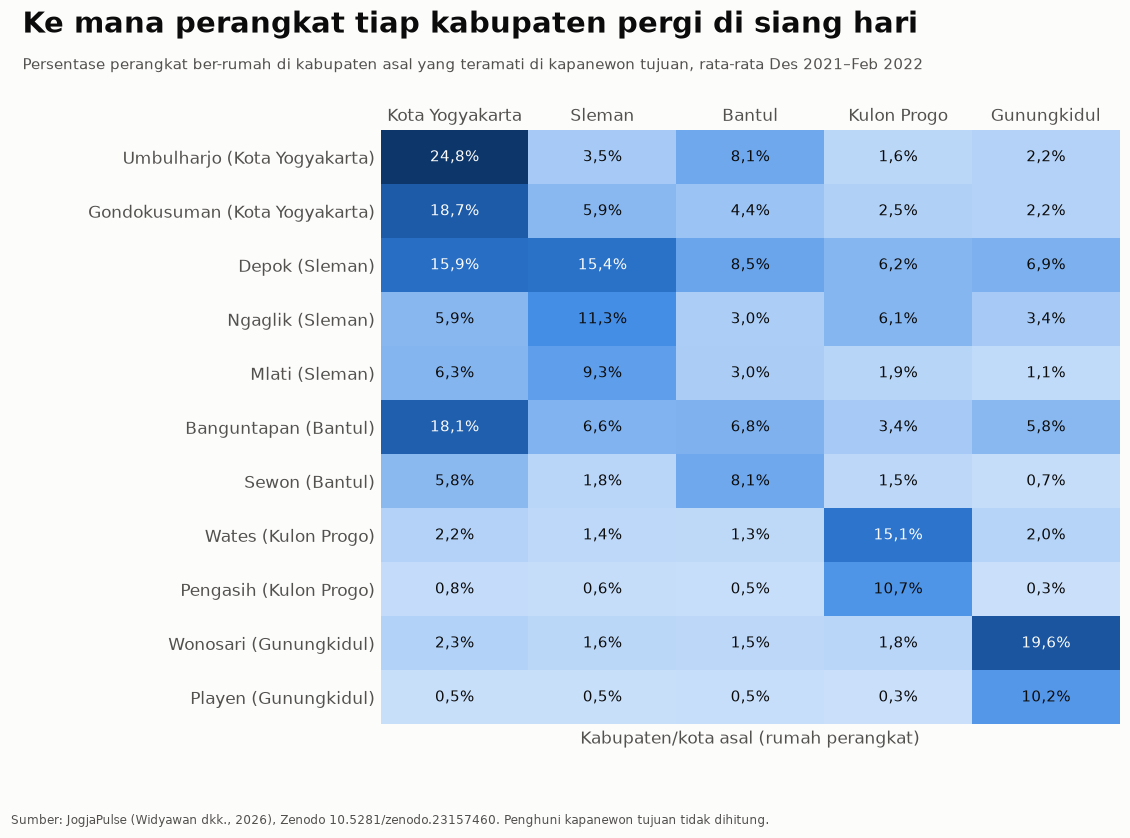

In [4]:
fig, ax = plt.subplots(figsize=(10.5, 7.4))
fig.subplots_adjust(left=0.33, right=0.97, top=0.83, bottom=0.1)
fig.text(0.02, 0.95, "Ke mana perangkat tiap kabupaten pergi di siang hari",
         fontsize=19, fontweight="bold")
fig.text(0.02, 0.905,
         "Persentase perangkat ber-rumah di kabupaten asal yang teramati di kapanewon tujuan, rata-rata Des 2021–Feb 2022",
         color=style.TEXT_SECONDARY, fontsize=10)

nilai = tampil.to_numpy()
im = ax.imshow(nilai, cmap=style.SEQUENTIAL_BLUE, aspect="auto", vmin=0, vmax=nilai.max())
ax.grid(False)
ax.set_xticks(range(nilai.shape[1]), tampil.columns)
ax.set_yticks(range(nilai.shape[0]), tampil.index)
ax.xaxis.tick_top()
ax.tick_params(length=0)
ax.set_xlabel("Kabupaten/kota asal (rumah perangkat)")
ax.xaxis.set_label_position("bottom")
for spine in ax.spines.values():
    spine.set_visible(False)
ambang_teks = nilai.max() * 0.55
for r in range(nilai.shape[0]):
    for c in range(nilai.shape[1]):
        v = nilai[r, c]
        ax.text(c, r, f"{v:.1f}%".replace(".", ","), ha="center", va="center", fontsize=10,
                color=style.SURFACE if v > ambang_teks else style.TEXT_PRIMARY)
style.add_source(fig, style.SOURCE_NOTE + ". Penghuni kapanewon tujuan tidak dihitung.")
style.save(fig, "D1_matriks_asal_tujuan")
plt.show()

## 3. Daya tarik tiap kapanewon

**Daya tarik** kapanewon *j* adalah persentase perangkat ber-rumah di luar *j* (seluruh DIY) yang teramati siang di *j*:

`jumlah n_maids dari semua asal i ≠ j / jumlah n_homed_maids_daytime semua i ≠ j`

Karena penyebutnya ikut turun bersama sampel, ukuran ini bisa dibandingkan antar bulan. Ukuran ini menghitung jangkauan pengunjung, bukan lamanya kunjungan atau jumlah perjalanan. Kapanewon yang dikelilingi wilayah padat penduduk cenderung mendapat nilai lebih tinggi.

Sebagai ukuran kedua kami menghitung **rasio pengunjung**, yaitu pengunjung dari luar dibagi perangkat ber-rumah di *j* sendiri. Rasio ini menonjolkan kapanewon kecil yang didatangi jauh lebih banyak perangkat daripada penghuninya.

In [5]:
def daya_tarik(od_bulan, rumah_bulan, tambah_supresi=0.0):
    luar = od_bulan[od_bulan["origin_code"] != od_bulan["dest_code"]]
    masuk = luar.groupby(["month", "dest_code"])["n_maids"].agg(["sum", "size"]).reset_index()
    sendiri = rumah_bulan.set_index(["month", "origin_code"])["n_homed_maids_daytime"].astype(float)
    total = rumah_bulan.groupby("month")["n_homed_maids_daytime"].sum().astype(float)
    n_asal = rumah_bulan.groupby("month")["origin_code"].nunique()
    idx = pd.MultiIndex.from_frame(masuk[["month", "dest_code"]])
    masuk["penghuni"] = sendiri.reindex(idx).to_numpy()
    # Batas atas: setiap pasangan asal-tujuan yang tidak terbit dianggap berisi 4 perangkat.
    hilang = masuk["month"].map(n_asal) - 1 - masuk["size"]
    masuk["pengunjung"] = masuk["sum"] + tambah_supresi * hilang
    masuk["daya_tarik"] = masuk["pengunjung"] / (masuk["month"].map(total) - masuk["penghuni"]) * 100
    masuk["rasio_pengunjung"] = masuk["pengunjung"] / masuk["penghuni"]
    return masuk


dt_bulanan = daya_tarik(od, rumah)
dt = (
    dt_bulanan.groupby("dest_code")[["daya_tarik", "rasio_pengunjung"]].mean()
    .reindex(lookup["kapanewon_code"])
    .rename_axis("kapanewon_code")
)
if dt.isna().any().any():
    raise ValueError("Semua 78 kapanewon harus punya nilai daya tarik.")

stabil = dt_bulanan.pivot(index="dest_code", columns="month", values="daya_tarik").corr(method="spearman")
print("Korelasi Spearman peringkat daya tarik antar bulan:")
display(stabil.round(3))

dt = dt.join(lookup.set_index("kapanewon_code")[["kab_kota", "kapanewon"]])
dt["peringkat"] = dt["daya_tarik"].rank(ascending=False).astype(int)
display(dt.sort_values("daya_tarik", ascending=False).head(10).round(2))
display(dt.sort_values("rasio_pengunjung", ascending=False).head(5).round(2))
display(dt.groupby("kab_kota")["daya_tarik"].describe()[["count", "min", "50%", "max"]]
        .reindex(style.KAB_ORDER).round(2))

Korelasi Spearman peringkat daya tarik antar bulan:


month,2021-12,2022-01,2022-02
month,,,
2021-12,1.000,0.943,0.890
2022-01,0.943,1.000,0.976
2022-02,0.890,0.976,1.000


,daya_tarik,rasio_pengunjung,kab_kota,kapanewon,peringkat
kapanewon_code,,,,,
34.04.07,12.19,1.28,SLEMAN,DEPOK,1
34.02.12,7.69,1.28,BANTUL,BANGUNTAPAN,2
34.04.12,7.46,1.08,SLEMAN,NGAGLIK,3
34.04.01,6.71,1.09,SLEMAN,GAMPING,4
34.04.06,6.24,1.72,SLEMAN,MLATI,5
34.71.03,6.23,4.25,YOGYAKARTA,GONDOKUSUMAN,6
34.71.13,6.19,1.75,YOGYAKARTA,UMBULHARJO,7
34.02.16,5.86,0.96,BANTUL,KASIHAN,8
34.04.16,4.91,1.60,SLEMAN,PAKEM,9


,daya_tarik,rasio_pengunjung,kab_kota,kapanewon,peringkat
kapanewon_code,,,,,
34.71.06,1.01,13.98,YOGYAKARTA,NGAMPILAN,42
34.71.05,1.39,11.36,YOGYAKARTA,GEDONGTENGEN,32
34.71.04,2.53,10.54,YOGYAKARTA,DANUREJAN,19
34.71.07,1.30,7.55,YOGYAKARTA,WIROBRAJAN,33
34.71.08,1.46,7.04,YOGYAKARTA,MANTRIJERON,31


,count,min,50%,max
kab_kota,,,,
YOGYAKARTA,14.0,1.01,2.46,6.23
SLEMAN,17.0,0.61,2.74,12.19
BANTUL,17.0,0.17,1.14,7.69
KULON PROGO,12.0,0.15,0.54,2.30
GUNUNGKIDUL,18.0,0.02,0.15,2.26


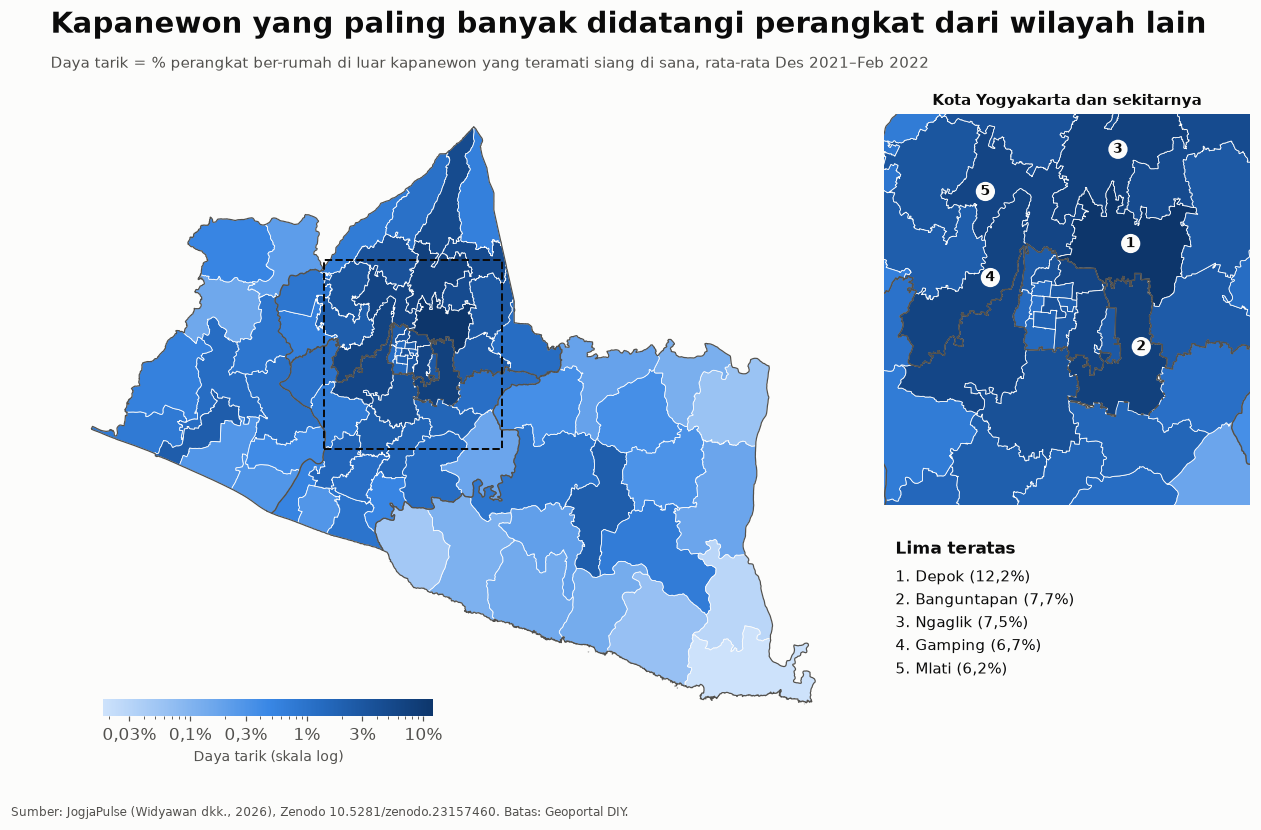

In [6]:
batas = maps.load_kapanewon_boundaries()
peta = maps.join_kapanewon_boundaries(dt.reset_index(), boundaries=batas).to_crs(epsg=32749)
if peta["daya_tarik"].isna().any():
    raise ValueError("Semua poligon harus mendapat nilai daya tarik.")
batas_kab = peta.dissolve(by="wadmkk").boundary
norma = LogNorm(vmin=peta["daya_tarik"].min(), vmax=peta["daya_tarik"].max())
top = peta.nsmallest(5, "peringkat")


def gambar(ax, label_top=False):
    peta.plot(ax=ax, column="daya_tarik", cmap=style.SEQUENTIAL_BLUE, norm=norma,
              edgecolor=style.SURFACE, linewidth=0.55)
    batas_kab.plot(ax=ax, color=style.TEXT_SECONDARY, linewidth=0.8)
    if label_top:
        for row in top.itertuples():
            p = row.geometry.representative_point()
            ax.annotate(f"{row.peringkat}", (p.x, p.y), ha="center", va="center", fontsize=9,
                        fontweight="bold", color=style.TEXT_PRIMARY,
                        bbox={"boxstyle": "circle,pad=0.2", "fc": style.SURFACE, "ec": "none"})
    ax.axis("off")


fig = plt.figure(figsize=(12, 7.4))
fig.text(0.04, 0.94, "Kapanewon yang paling banyak didatangi perangkat dari wilayah lain",
         fontsize=19, fontweight="bold")
fig.text(0.04, 0.897,
         "Daya tarik = % perangkat ber-rumah di luar kapanewon yang teramati siang di sana, rata-rata Des 2021–Feb 2022",
         color=style.TEXT_SECONDARY, fontsize=10)
ax = fig.add_axes([0.035, 0.08, 0.62, 0.78])
gambar(ax)
detail = fig.add_axes([0.66, 0.36, 0.3, 0.48])
gambar(detail, label_top=True)
inti = peta[peta["kab_kota"].eq("YOGYAKARTA")].total_bounds
pad = 8000
kiri, bawah, kanan, atas = inti[0] - pad, inti[1] - pad, inti[2] + pad, inti[3] + pad
detail.set(xlim=(kiri, kanan), ylim=(bawah, atas))
detail.set_title("Kota Yogyakarta dan sekitarnya", fontsize=10, loc="center")
ax.add_patch(Rectangle((kiri, bawah), kanan - kiri, atas - bawah, fill=False,
                       edgecolor=style.TEXT_PRIMARY, linestyle="--", linewidth=1.3, zorder=5))

daftar = "\n".join(
    f"{r.peringkat}. {r.kapanewon.title()} ({r.daya_tarik:.1f}%)".replace(f"{r.daya_tarik:.1f}", f"{r.daya_tarik:.1f}".replace(".", ","))
    for r in top.itertuples()
)
fig.text(0.68, 0.30, "Lima teratas", fontsize=11, fontweight="bold")
fig.text(0.68, 0.285, daftar, fontsize=10, va="top", linespacing=1.5)

cax = fig.add_axes([0.08, 0.1, 0.25, 0.022])
cb = fig.colorbar(plt.cm.ScalarMappable(norm=norma, cmap=style.SEQUENTIAL_BLUE), cax=cax,
                  orientation="horizontal")
cb.set_ticks([0.03, 0.1, 0.3, 1, 3, 10])
cb.set_ticklabels(["0,03%", "0,1%", "0,3%", "1%", "3%", "10%"])
cb.set_label("Daya tarik (skala log)", fontsize=9)
cb.outline.set_visible(False)
style.add_source(fig, style.SOURCE_NOTE + ". Batas: Geoportal DIY.")
style.save(fig, "D2_peta_daya_tarik")
plt.show()

## 4. Sambungan ke bagian B: apakah kapanewon puncak siang lebih menarik pengunjung?

Bagian A menduga puncak siang menandai pusat kegiatan, dan mencatat bahwa puncak siang di Gunungkidul bisa juga berasal dari pasar, pertanian, atau supresi jam malam. Bagian D menguji satu sisi dugaan itu, yaitu apakah kapanewon puncak siang juga banyak didatangi perangkat dari kapanewon lain.

Perbandingan langsung antar klaster bisa menyesatkan karena komposisi kabupatennya berbeda. Contohnya, 15 dari 18 kapanewon Gunungkidul berada di klaster puncak siang, padahal Gunungkidul jauh dari pusat kota. Karena itu kami membandingkan klaster **di dalam kabupaten yang sama**. Statistiknya adalah rata-rata selisih median log daya tarik (siang dikurangi petang) di kabupaten yang punya kedua klaster. Nilai p dihitung dengan mengacak label klaster di dalam tiap kabupaten sebanyak 9.999 kali. Tiga profil tak lazim dari B tidak diikutkan.

In [7]:
gabung = dt.join(klaster.set_index("kapanewon_code")[["klaster", "supresi_tinggi"]])
gabung["log_dt"] = np.log10(gabung["daya_tarik"])
utama = gabung[gabung["klaster"].isin(KLASTER_UTAMA)].copy()

display(gabung.groupby("klaster")["daya_tarik"].agg(["count", "median"]).round(2))
mw = stats.mannwhitneyu(
    utama.loc[utama["klaster"].eq("Puncak siang"), "daya_tarik"],
    utama.loc[utama["klaster"].eq("Puncak petang"), "daya_tarik"],
)
print(f"Tanpa memperhitungkan kabupaten: Mann-Whitney U = {mw.statistic:.0f}, p = {mw.pvalue:.3f}")

per_kab = utama.pivot_table(index="kab_kota", columns="klaster", values="daya_tarik",
                            aggfunc=["median", "count"]).reindex(style.KAB_ORDER)
display(per_kab.round(2))


def uji_permutasi(data):
    # Hanya kabupaten yang punya kedua klaster utama yang ikut dihitung.
    grup = []
    for _, g in data.groupby("kab_kota"):
        siang = g["klaster"].eq("Puncak siang").to_numpy()
        if 0 < siang.sum() < len(g):
            grup.append((g["log_dt"].to_numpy(), siang))

    def statistik(label_per_grup):
        return np.mean([np.median(y[s]) - np.median(y[~s]) for (y, _), s in zip(grup, label_per_grup)])

    amatan = statistik([s for _, s in grup])
    rng = np.random.default_rng(SEED)
    acak = np.array([statistik([rng.permutation(s) for _, s in grup]) for _ in range(N_PERMUTASI)])
    p = (np.sum(np.abs(acak) >= abs(amatan)) + 1) / (N_PERMUTASI + 1)
    return float(amatan), len(grup), float(p)


amatan, n_kab, p_perm = uji_permutasi(utama)
print(
    f"Dalam kabupaten yang sama ({n_kab} kabupaten): median daya tarik puncak siang "
    f"{10 ** amatan:.2f} kali puncak petang, p permutasi = {p_perm:.3f}"
)

,count,median
klaster,,
Profil tak lazim,3,0.03
Puncak petang,39,1.30
Puncak siang,36,0.82


Tanpa memperhitungkan kabupaten: Mann-Whitney U = 491, p = 0.026


median                      count             
klaster     Puncak petang Puncak siang Puncak petang Puncak siang
kab_kota                                                         
YOGYAKARTA           2.40         2.34             7            6
SLEMAN               2.48         4.02            13            4
BANTUL               1.13         1.52            14            3
KULON PROGO          0.28         0.82             4            8
GUNUNGKIDUL          0.05         0.18             1           15

Dalam kabupaten yang sama (5 kabupaten): median daya tarik puncak siang 1.87 kali puncak petang, p permutasi = 0.048


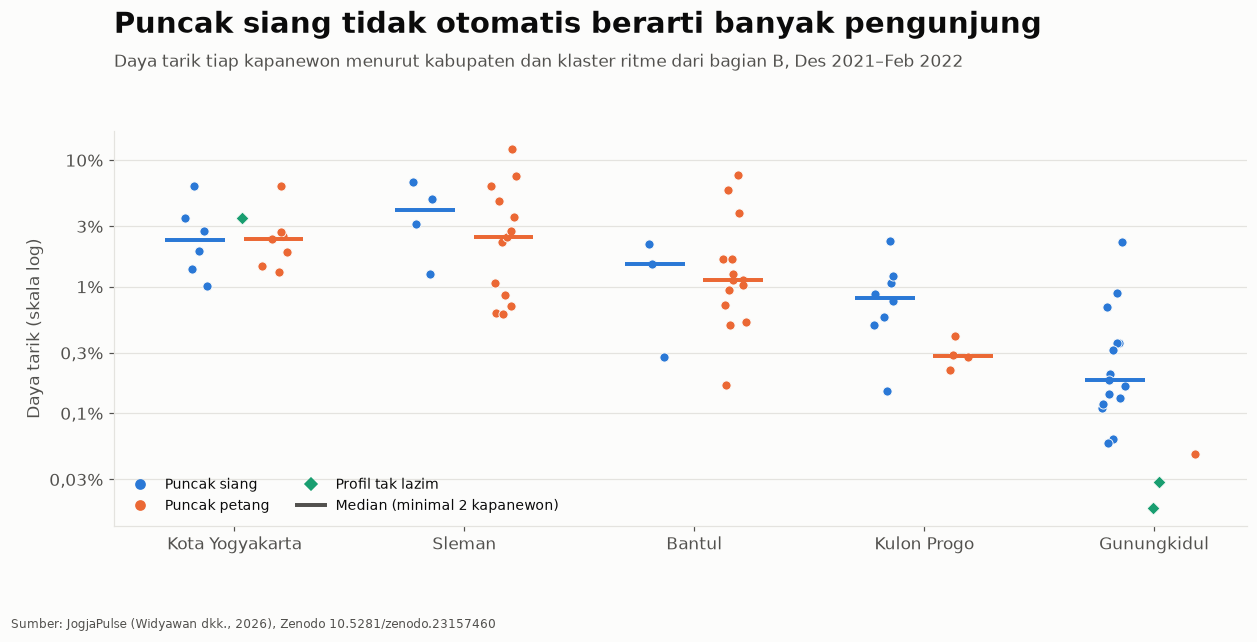

In [8]:
fig, ax = plt.subplots(figsize=(11.7, 5.6))
fig.subplots_adjust(left=0.09, right=0.97, top=0.78, bottom=0.14)
fig.text(0.09, 0.94, "Puncak siang tidak otomatis berarti banyak pengunjung",
         fontsize=19, fontweight="bold")
fig.text(0.09, 0.885,
         "Daya tarik tiap kapanewon menurut kabupaten dan klaster ritme dari bagian B, Des 2021–Feb 2022",
         color=style.TEXT_SECONDARY)

rng = np.random.default_rng(SEED)
geser = {"Puncak siang": -0.17, "Puncak petang": 0.17, "Profil tak lazim": 0.0}
for i, k in enumerate(style.KAB_ORDER):
    for nama_klaster, g in gabung[gabung["kab_kota"].eq(k)].groupby("klaster"):
        x = i + geser[nama_klaster] + rng.uniform(-0.06, 0.06, len(g))
        ax.scatter(x, g["daya_tarik"], s=36, color=WARNA_KLASTER[nama_klaster],
                   edgecolor=style.SURFACE, linewidth=0.6, zorder=3,
                   marker="o" if nama_klaster != "Profil tak lazim" else "D")
        if nama_klaster in KLASTER_UTAMA and len(g) >= 2:
            m = g["daya_tarik"].median()
            ax.hlines(m, i + geser[nama_klaster] - 0.13, i + geser[nama_klaster] + 0.13,
                      color=WARNA_KLASTER[nama_klaster], linewidth=2.6, zorder=4)

ax.set_yscale("log")
ax.set_yticks([0.03, 0.1, 0.3, 1, 3, 10], ["0,03%", "0,1%", "0,3%", "1%", "3%", "10%"])
ax.minorticks_off()
ax.set_xticks(range(len(style.KAB_ORDER)), [style.KAB_LABELS[k] for k in style.KAB_ORDER])
ax.set_ylabel("Daya tarik (skala log)")
ax.legend(
    handles=[
        Line2D([], [], marker="o", linestyle="", color=WARNA_KLASTER["Puncak siang"], label="Puncak siang"),
        Line2D([], [], marker="o", linestyle="", color=WARNA_KLASTER["Puncak petang"], label="Puncak petang"),
        Line2D([], [], marker="D", linestyle="", color=WARNA_KLASTER["Profil tak lazim"], label="Profil tak lazim"),
        Line2D([], [], color=style.TEXT_SECONDARY, linewidth=2.6, label="Median (minimal 2 kapanewon)"),
    ],
    loc="lower left", fontsize=9, ncols=2,
)
style.add_source(fig)
style.save(fig, "D3_daya_tarik_per_klaster")
plt.show()

## 5. Uji sensitivitas

Kami mengecek apakah peringkat daya tarik dan hasil perbandingan klaster berubah kalau:

1. pasangan asal–tujuan yang tersupresi dianggap berisi 4 perangkat (batas atas supresi);
2. periode diperpanjang sampai April 2022, termasuk bulan berkualitas rendah;
3. ukuran diganti dengan rasio pengunjung terhadap penghuni;
4. sembilan kapanewon dengan supresi jam tinggi dari B dikeluarkan dari perbandingan klaster.

Untuk peringkat dipakai korelasi Spearman terhadap ukuran utama dan jumlah anggota lima teratas yang sama.

In [9]:
def ringkas_varian(label, nilai):
    nilai = nilai.reindex(dt.index)
    top5_utama = set(dt["daya_tarik"].nlargest(5).index)
    return {
        "varian": label,
        "spearman_vs_utama": stats.spearmanr(dt["daya_tarik"], nilai).statistic,
        "top5_sama": len(top5_utama & set(nilai.nlargest(5).index)),
    }


batas_atas = daya_tarik(od, rumah, tambah_supresi=4).groupby("dest_code")["daya_tarik"].mean()
lima_bulan = daya_tarik(od_semua, rumah_semua.dropna(subset=["n_homed_maids_daytime"]))
lima_bulan = lima_bulan.groupby("dest_code")["daya_tarik"].mean()

sens_peringkat = pd.DataFrame([
    ringkas_varian("Batas atas supresi (+4 per pasangan hilang)", batas_atas),
    ringkas_varian("Desember–April (termasuk kualitas rendah)", lima_bulan),
    ringkas_varian("Rasio pengunjung terhadap penghuni", dt["rasio_pengunjung"]),
]).set_index("varian")
display(sens_peringkat.round(3))


def uji_varian(label, nilai_dt, pilih=None):
    data = gabung.assign(daya_tarik=nilai_dt.reindex(gabung.index))
    data["log_dt"] = np.log10(data["daya_tarik"])
    data = data[data["klaster"].isin(KLASTER_UTAMA)]
    if pilih is not None:
        data = data[pilih.reindex(data.index)]
    a, n, p = uji_permutasi(data)
    return {"varian": label, "n_kapanewon": len(data), "n_kabupaten": n,
            "kali_lipat_siang_vs_petang": 10 ** a, "p_permutasi": p}


sens_klaster = pd.DataFrame([
    uji_varian("Utama", dt["daya_tarik"]),
    uji_varian("Batas atas supresi", batas_atas),
    uji_varian("Desember–April", lima_bulan),
    uji_varian("Rasio pengunjung terhadap penghuni", dt["rasio_pengunjung"]),
    uji_varian("Tanpa 9 kapanewon supresi tinggi", dt["daya_tarik"], ~gabung["supresi_tinggi"]),
]).set_index("varian")
sens_klaster.round(3)

,spearman_vs_utama,top5_sama
varian,,
Batas atas supresi (+4 per pasangan hilang),1.000,5
Desember–April (termasuk kualitas rendah),0.991,3
Rasio pengunjung terhadap penghuni,0.435,0


,n_kapanewon,n_kabupaten,kali_lipat_siang_vs_petang,p_permutasi
varian,,,,
Utama,75,5,1.871,0.048
Batas atas supresi,75,5,1.338,0.144
Desember–April,75,5,2.005,0.033
Rasio pengunjung terhadap penghuni,75,5,1.273,0.137
Tanpa 9 kapanewon supresi tinggi,68,4,1.632,0.073


## Simpan hasil

Tabel daya tarik per kapanewon disimpan ke `data/processed/` (tidak di-commit) untuk dipakai di slide atau bagian lain.

In [10]:
simpan = gabung.reset_index()[[
    "kapanewon_code", "kab_kota", "kapanewon", "daya_tarik", "rasio_pengunjung",
    "peringkat", "klaster", "supresi_tinggi",
]]
out = io.PROCESSED_DIR / "D_daya_tarik_kapanewon.csv"
simpan.to_csv(out, index=False)
mat.to_csv(io.PROCESSED_DIR / "D_matriks_kabupaten_ke_kapanewon.csv")
print(f"{len(simpan)} baris disimpan ke {out.relative_to(io.ROOT)}")

78 baris disimpan ke data/processed/D_daya_tarik_kapanewon.csv


## Temuan

Analisis memakai Desember 2021–Februari 2022, 78 kapanewon asal setiap bulan, dan penyebut perangkat ber-rumah yang teramati siang hari (112.475, 77.312, dan 64.269 perangkat).

### 1. Kunjungan siang sebagian besar tetap dekat rumah, dan tiap kabupaten punya pusatnya sendiri

- Median 94,1% perangkat teramati siang hari di kapanewon rumahnya sendiri.
- Kunjungan ke kapanewon lain terkumpul di pusat masing-masing kabupaten. Wonosari didatangi 19,6% perangkat Gunungkidul, Wates 15,1% perangkat Kulon Progo, dan Umbulharjo 24,8% perangkat Kota Yogyakarta (grafik D1).
- Depok adalah satu-satunya tujuan yang didatangi minimal 6% perangkat dari **setiap** kabupaten (6,2–15,9%).
- Perangkat Kota Yogyakarta juga banyak tercatat di Banguntapan (18,1%), kapanewon Bantul yang berbatasan langsung dengan kota.

### 2. Daya tarik tertinggi ada di cincin sekitar Kota Yogyakarta

- Lima teratas adalah Depok (12,2%), Banguntapan (7,7%), Ngaglik (7,5%), Gamping (6,7%), dan Mlati (6,2%). Semuanya berada di Sleman atau Bantul dan berbatasan dengan kota (grafik D2).
- Kapanewon di Kota Yogyakarta luasnya kecil, sehingga persentasenya lebih rendah. Namun jika dibandingkan dengan jumlah penghuninya, Kota memimpin. Ngampilan didatangi sekitar 14 kali jumlah perangkat penghuninya, Gedongtengen 11 kali, dan Danurejan 11 kali.
- Peringkat daya tarik stabil antar bulan (Spearman 0,89–0,98). Peringkat juga tidak berubah ketika pasangan yang tersupresi dianggap berisi 4 perangkat (Spearman 1,00, lima teratas sama).
- Kapanewon yang paling jarang didatangi semuanya di Gunungkidul. Girisubo, Rongkop, Purwosari, Semin, dan Tepus berada di bawah 0,1%.

### 3. Puncak siang hanya lemah berkaitan dengan banyaknya pengunjung

- Jika dibandingkan langsung, klaster puncak siang justru punya median daya tarik lebih rendah (0,82%) daripada puncak petang (1,30%), p = 0,026. Penyebabnya, 15 dari 18 kapanewon Gunungkidul berada di klaster puncak siang tetapi jarang didatangi dari luar (grafik D3).
- Di dalam kabupaten yang sama, kapanewon puncak siang rata-rata punya daya tarik 1,9 kali puncak petang (p permutasi 0,048). Di Kota Yogyakarta keduanya hampir sama.
- Hasil dalam kabupaten ini **tidak kuat**. Nilai p naik ke 0,07–0,14 pada tiga dari empat uji sensitivitas.
- Artinya, puncak siang belum tentu menandai tempat yang menarik pengunjung dari luar. Di Gunungkidul, puncak siang lebih mungkin berasal dari kegiatan penghuni sendiri atau dari supresi jam malam, sesuai catatan bagian A. Label "pusat kegiatan" pada bagian B tetap asumsi.

### Batas pembacaan

- Angka ini menghitung perangkat pengunjung unik per bulan, bukan jumlah perjalanan, lama kunjungan, atau rute. Satu ping siang hari sudah cukup untuk dihitung sebagai kunjungan.
- Rumah bulanan adalah perkiraan dari lokasi malam. Perangkat tidak sama dengan orang, dan sampelnya tidak acak.
- Daya tarik adalah batas bawah karena sekitar 5% arus antar kapanewon hilang akibat supresi.
- Ukuran daya tarik cenderung tinggi untuk kapanewon yang bertetangga dengan wilayah padat penduduk. Rasio pengunjung terhadap penghuni memberi gambaran pelengkap.
- Maret–April 2022 tidak dipakai di hasil utama karena kualitas OD menurun.